<a href="https://colab.research.google.com/github/OjasRaj/TechSoc_AIML_Orientation_HandsOn/blob/main/ML_Hands_On_TechSoc_OR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Hands-On: Classifying Tumor Diagnostics

## The Problem We Are Solving

### We want to predict whether a tumor is malignant (1 for Yes) or benign (0 for No) based on medical measurements of the cell nuclei.

### What is Classification?
Unlike regression where we predict numerical values, Classification is the task of predicting a category, class, or label.
* **Regression:** Predicts continuous values (e.g., predicting exact tumor size).
* **Classification:** Predicts discrete categories (e.g., predicting malignant vs. benign).

## Step 1: Loading a Real Dataset (Cancer Wisconsin)
Instead of generating synthetic data, we will use a famous real-world dataset built into scikit-learn.

* **Input (Feature):** Mean radius of the tumor cells.
* **Output (Target):** Diagnosis (0 = Benign, 1 = Malignant).

,Mean_Radius,Malignant
0,17.99,0
1,20.57,0
2,19.69,0
3,11.42,0
4,20.29,0


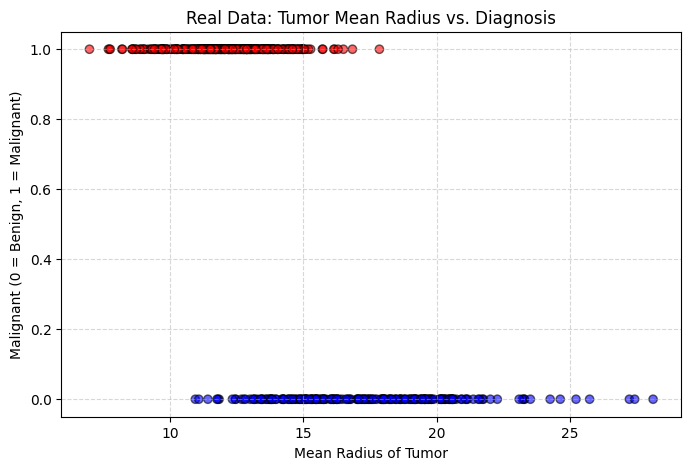

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

# Load the real dataset
cancer_data = load_breast_cancer()

# We will use the 'mean radius' column as our single feature to keep things easy to visualize
X = cancer_data.data[:, 0]
y = cancer_data.target

# Convert to a friendly table (DataFrame) so we can look at it
data = pd.DataFrame({'Mean_Radius': X, 'Malignant': y})
display(data.head())

# Visualize the real data distribution
plt.figure(figsize=(8, 5))
plt.scatter(data['Mean_Radius'], data['Malignant'], c=data['Malignant'], cmap='bwr', alpha=0.6, edgecolors='k', label='Patients')
plt.title('Real Data: Tumor Mean Radius vs. Diagnosis')
plt.xlabel('Mean Radius of Tumor')
plt.ylabel('Malignant (0 = Benign, 1 = Malignant)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Test-Train Split:
If you study for a test by looking at the exact questions that will be on the exam, you haven't actually learned—you just memorized!

To prevent our machine from just "memorizing" the answers, we split our data into two parts:
1. **Training Set (80%)**: The "practice textbook" the machine uses to study the relationship between tumor sizes and diagnosis.
2. **Testing Set (20%)**: The "final exam" containing data the machine has never seen before. We use this to grade how smart our model actually is.

In [8]:
from sklearn.model_selection import train_test_split

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Total data points: {len(X)}")
print(f"Training data points (the textbook): {len(X_train)}")
print(f"Testing data points (the final exam): {len(X_test)}")

Total data points: 200
Training data points (the textbook): 160
Testing data points (the final exam): 40


## Step 3: Cleaning Up the Noise
Sometimes, real-world biological data contains highly unusual patient records (anomalies). We will check and clean the training set by keeping patient measurements that fall within the typical medical range.

In [17]:
# We will clean our training set to make sure our model learns from typical cases
train_df = pd.DataFrame({'X': X_train, 'y': y_train})

# Identify extreme statistical outliers based on the mean radius
radius_mean = train_df['X'].mean()
radius_std = train_df['X'].std()

# Keep patient records that fall within 2 standard deviations of the average tumor size
clean_train_df = train_df[abs(train_df['X'] - radius_mean) < (2.0 * radius_std)]

X_train_clean = clean_train_df['X'].values.reshape(-1, 1)
y_train_clean = clean_train_df['y'].values

# Reshape the test set for predictions
X_test_reshaped = X_test.reshape(-1, 1)

print(f"Original training size: {len(X_train)} patients")
print(f"Cleaned training size: {len(X_train_clean)} patients (Removed {len(X_train) - len(X_train_clean)} extreme outliers)")

Original training size: 160 patients
Cleaned training size: 156 patients (Removed 4 extreme outliers)


## Step 4: Meet the "Decision Tree" Model

### What is a Decision Tree?
Imagine playing a game of **20 Questions**. You ask:
1. *"Is the mean radius of the tumor cells greater than 15.0?"* (Yes/No)

By following this path of simple choices, the tree eventually reaches a decision label: **Benign (0)** or **Malignant (1)**.

### Key Knob to Turn (Hyperparameter):
* **`max_depth=3`**: This tells our tree it can only ask a maximum of 3 consecutive questions. This prevents it from building overcomplicated rules.

In [10]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the classification model with a max depth of 3
model = DecisionTreeClassifier(max_depth=3, random_state=42)

# Train the model using our cleaned training data
model.fit(X_train_clean, y_train_clean)

# Have the trained model make predictions on our exam (test set)
predictions = model.predict(X_test_reshaped)

print("Model training complete!")
print("Current Decision Tree parameters:")
print(model.get_params())

Model training complete!
Current Decision Tree parameters:
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


## Step 5: Grading the Exam (How Well Did We Do?)

In classification, we predict exact category answers (Benign or Malignant). Because of this, we evaluate accuracy by looking at how many correct and incorrect classifications we made.

### 1. Classification Accuracy
* **Definition in short:** The percentage of overall diagnoses that the model got exactly correct.
* **In simple terms:** "Out of 100 patient cases, how many did we correctly diagnose?"

### 2. Precision
* **Definition in short:** The proportion of predicted positives that were actually positive.
* **In simple terms:** "When we predicted a tumor was malignant, how often were we actually right?"

### 3. Recall (Sensitivity)
* **Definition in short:** The proportion of actual positives that were correctly identified.
* **In simple terms:** "Out of all the tumors that were actually malignant, what percentage did our model successfully catch?"

### 4. F1-Score
* **Definition in short:** The harmonic mean of Precision and Recall.
* **In simple terms:** A balanced score that is only high when both Precision and Recall are strong.

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate our performance metrics
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

# Display the results clearly
print("=== PERFORMANCE EVALUATION ===")
print(f"Accuracy Score: {accuracy:.4f} (or {accuracy*100:.2f}%)")
print(f"Precision Score: {precision:.4f} (or {precision*100:.2f}%)")
print(f"Recall Score: {recall:.4f} (or {recall*100:.2f}%)")
print(f"F1 Accuracy Score: {f1:.4f} (or {f1*100:.2f}%)")

=== PERFORMANCE EVALUATION ===
Accuracy Score: 0.7750 (or 77.50%)
Precision Score: 0.8182 (or 81.82%)
Recall Score: 0.7826 (or 78.26%)
F1 Accuracy Score: 0.8000 (or 80.00%)


## Step 6: Visualizing the Model's Predictions
Let's plot our test set data points and draw the Decision Tree's step-like prediction line to show where the model draws the boundary line between "Benign" and "Malignant".

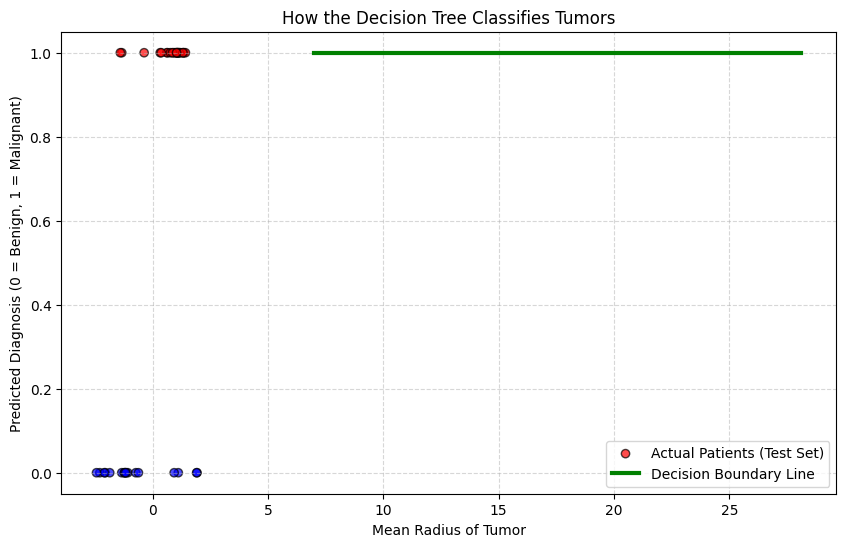

In [18]:
# Create a continuous line of inputs to plot the step decision boundary smoothly
X_line = np.linspace(X.min(), X.max(), 500).reshape(-1, 1)
y_line = model.predict(X_line)

plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, c=y_test, cmap='bwr', alpha=0.7, edgecolors='k', label='Actual Patients (Test Set)')
plt.plot(X_line, y_line, color='green', linewidth=3, label='Decision Boundary Line')
plt.title('How the Decision Tree Classifies Tumors')
plt.xlabel('Mean Radius of Tumor')
plt.ylabel('Predicted Diagnosis (0 = Benign, 1 = Malignant)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Summary of the Machine Learning Pipeline

We have completed the classification pipeline successfully:
1. **Data Generation**: Simulated 200 customer sessions based on site browsing times.
2. **Test-Train Split**: Divided the dataset into training (80%) and testing (20%) subsets.
3. **Data Cleaning**: Identified and removed 3 boundary noise data points.
4. **Model Training**: Fitted a Decision Tree Classifier with a max depth of 3.
5. **Performance Evaluation**: Obtained a final Accuracy of **77.50%** and an F1 Accuracy Score of **80.00%** on the unseen test set.

## Appendix: Additional Resources

For more details on machine learning, classification parameters, or scikit-learn, you can consult the official documentation.